# Causality companions — v2 C++ probe stub (`causality_auto`)

Companions of every paper figure that reports **causality**, with the causality readouts taken from the
**v2 probe** (`auto func (auto value){` + "You are implementing a C++ function. Just write the function body ...",
`scripts/evaluation/run_causal_v2.py` on `dev`) instead of the paper's `bool check(auto value){` stub.
Faithfulness is unchanged (read from `results/`). Every run config (strategy, alpha, layers, heads, seed, rubric)
matches the paper's leaf; only the stub differs.

| paper | source generator (cells) | here |
|---|---|---|
| Fig 2 (right) + Fig 12 `fig:heads-vs-residual` | `readout_sources_and_head_budget` (8) | `source_comparison` |
| App E.2 `fig:sparsity`, `fig:sparsity-other-pivots` | `readout_sources_and_head_budget` (3, 5, 7) | `sparsity_sweep`, `sparsity_by_pivot` |
| App F `fig:comparison-{size,code,rl}` | `model_generalization` (1, 2), changed: replace at each model's best causality_auto α, faithfulness at the same α | `{model_size,code_finetuning,rl_finetuning}` (faithfulness | causality side by side) |
| App F `fig:comparison-code`, option B (pending decision) | — | `fig16_code_finetuning__optB_additive_coder122` (additive_norm 0.1, 122 Coder heads); option A = `fig16_code_finetuning__optA_replace_best_alpha` |
| App G `fig:ovreader`, `fig:ov-causality` | `ovreader` (2, 4, 5) | `ov_reader_combined`, `ov_by_pivot_combined` |

Roots: GoalScope causality `results_causal_v2/`; OVReader causality `results_causal_v2_nurc_20261106/results/`.
All outputs -> `notebooks/Figures/causality_auto/`, prefixed with the paper's current figure number (`figNN_`; Fig 2's right panel and Fig 12 are the same plot). Plotting code is copied verbatim from the source cells;
only the read roots and the save group change. Built by a script — rebuild only if the sources change.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
V2_GS   = os.path.join(env_utils.PROJECT_ROOT, "results")            # GoalScope causality_auto leaves (heads=...__stub=func)
V2_OV   = os.path.join(env_utils.PROJECT_ROOT, "results")            # OVReader causality_auto leaves (ov_reader/.../__stub=func)
OUT     = "causality_auto"
for p in (V2_GS, V2_OV): assert os.path.isdir(p), p
# PDFs only (the paper uses the PDFs): every save_fig below defaults to also_png=False
import figstyle as _fs
_save_fig = _fs.save_fig
_fs.save_fig = lambda fig, group, name, also_png=False: _save_fig(fig, group, name, also_png=also_png)

## Head budget (App E.2) and readout sources (Fig 2 right, Fig 12) — Qwen2.5-Coder-32B, additive_norm α 0.1

In [2]:
import glob, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rich import print as rich_print
from rich.table import Table
from rich.box import SIMPLE_HEAVY

import figstyle
figstyle.set_style()

MODEL = "Qwen2.5-Coder-32B-Instruct"
STRATEGY, ALPHA = "additive_norm", "0.1"
PIVOTS = figstyle.PIVOTS            # ["prev_end","indent","var","eq"] -- NEVER first_impl
COLOR = figstyle.MODEL_COLOR[MODEL]
GROUP = OUT  # legacy notebooks/Figures/<group> dir name, kept for compatibility
print("pivots:", PIVOTS)

pivots: ['prev_end', 'indent', 'var', 'eq']


In [3]:
# ── parse every head-set leaf's summary.json ────────────────────────────────
BASE = os.path.join(env_utils.PROJECT_ROOT, "results", "goalscope", MODEL)

def head_count(leaf_name: str) -> int:
    """Head budget from the leaf dir name. json:...top<k> -> k; the canonical
    threshold-selected `goal` set (heads=goal__..., no `json:`) is 122."""
    m = re.search(r"top(\d+)", leaf_name)
    if m:
        return int(m.group(1))
    if leaf_name.startswith("heads=goal__") and "json" not in leaf_name:
        return 122
    raise ValueError(f"cannot parse head count from {leaf_name!r}")

BASE_V2 = os.path.join(V2_GS, "goalscope", MODEL)

def load_metric(metric: str) -> pd.DataFrame:
    root = os.path.join(BASE_V2 if metric == "causality" else BASE, metric, STRATEGY, ALPHA)
    rows = []
    for leaf in glob.glob(os.path.join(root, "heads=*")):
        if not re.match(r"heads=(json:)?goal__", os.path.basename(leaf)):
            continue  # goal-head budgets only (skip e.g. the json:control122 control run)
        sm = os.path.join(leaf, "summary.json")
        if not os.path.exists(sm):
            continue
        s = json.load(open(sm))
        k = head_count(os.path.basename(leaf))
        by = s["by_anchor"]
        row = {"n_heads": k, "metric": metric,
               "overall": s["overall"]["hard_yes"],
               "n_records": s.get("n_records"),
               "mean_pivots": float(np.mean([by[p]["hard_yes"] for p in PIVOTS]))}
        row.update({p: by[p]["hard_yes"] for p in PIVOTS})
        rows.append(row)
    return pd.DataFrame(rows).sort_values("n_heads").reset_index(drop=True)

faith = load_metric("faithfulness")
caus  = load_metric("causality")
KS = sorted(faith.n_heads.unique())
assert KS == [5,10,25,50,100,122,150,200,250,300], KS
print("head budgets:", KS)
faith

head budgets: [np.int64(5), np.int64(10), np.int64(25), np.int64(50), np.int64(100), np.int64(122), np.int64(150), np.int64(200), np.int64(250), np.int64(300)]


,n_heads,metric,overall,n_records,mean_pivots,prev_end,indent,var,eq
0,5,faithfulness,0.445850,1265,0.362648,0.098814,0.371542,0.233202,0.747036
1,10,faithfulness,0.715415,1265,0.667984,0.335968,0.743083,0.683794,0.909091
2,25,faithfulness,0.791304,1265,0.750000,0.450593,0.798419,0.814229,0.936759
3,50,faithfulness,0.817391,1265,0.782609,0.561265,0.865613,0.747036,0.956522
4,100,faithfulness,0.867194,1265,0.839921,0.608696,0.901186,0.881423,0.968379
5,122,faithfulness,0.879051,1265,0.852767,0.588933,0.944664,0.905138,0.972332
6,150,faithfulness,0.859289,1265,0.830040,0.529644,0.897233,0.928854,0.964427
7,200,faithfulness,0.879842,1265,0.854743,0.616601,0.916996,0.905138,0.980237
8,250,faithfulness,0.852174,1265,0.823123,0.498024,0.893281,0.924901,0.976285
9,300,faithfulness,0.874308,1265,0.848814,0.604743,0.901186,0.920949,0.968379


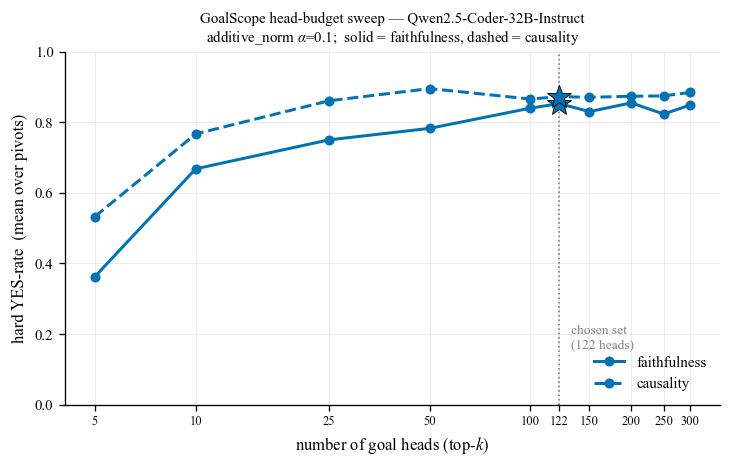

In [4]:
# ── Figure 1: two lines, mean-over-pivots vs head budget ────────────────────
fig, ax = plt.subplots(figsize=(6.2, 4.0))
for metric, df, ls in [("faithfulness", faith, "-"), ("causality", caus, "--")]:
    ax.plot(df.n_heads, df.mean_pivots, marker="o", ls=ls, color=COLOR, lw=1.8,
            ms=5, label=metric, zorder=3)
    # highlight the chosen 122-head set
    y122 = float(df.loc[df.n_heads == 122, "mean_pivots"].iloc[0])
    ax.plot([122], [y122], marker="*", ms=15, color=COLOR,
            markeredgecolor="black", markeredgewidth=0.5, zorder=5)

ax.axvline(122, color="grey", ls=":", lw=1, zorder=1)
ax.annotate("chosen set\n(122 heads)", xy=(122, ax.get_ylim()[0]),
            xytext=(132, 0.16), fontsize=8, color="grey")

ax.set_xscale("log")
ax.set_xticks(KS)
ax.set_xticklabels([str(k) for k in KS], fontsize=7.5)
ax.minorticks_off()
ax.set_xlabel("number of goal heads (top-$k$)")
ax.set_ylabel("hard YES-rate  (mean over pivots)")
ax.set_ylim(0, 1)
ax.set_title(f"GoalScope head-budget sweep — {MODEL}\nadditive_norm $\\alpha$=0.1;  "
             "solid = faithfulness, dashed = causality", fontsize=9)
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout()
figstyle.save_fig(fig, GROUP, "fig13_sparsity_sweep")
plt.show()

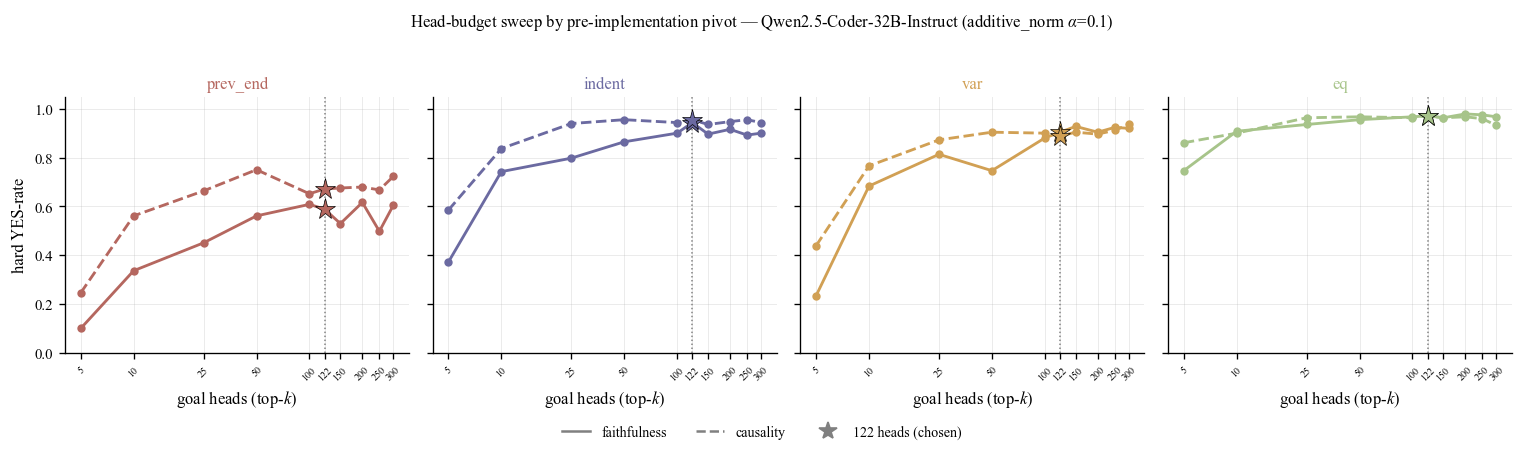

In [5]:
# ── Figure 2: per-pivot small multiples (appendix head_budget_preimplementation) ──
fig, axes = plt.subplots(1, len(PIVOTS), figsize=(3.2 * len(PIVOTS), 3.4), sharey=True)
for ax, piv in zip(axes, PIVOTS):
    pc = figstyle.PIVOT_COLOR[piv]
    for metric, df, ls in [("faithfulness", faith, "-"), ("causality", caus, "--")]:
        ax.plot(df.n_heads, df[piv], marker="o", ls=ls, color=pc, lw=1.7, ms=4,
                label=metric, zorder=3)
        y122 = float(df.loc[df.n_heads == 122, piv].iloc[0])
        ax.plot([122], [y122], marker="*", ms=13, color=pc,
                markeredgecolor="black", markeredgewidth=0.4, zorder=5)
    ax.axvline(122, color="grey", ls=":", lw=0.9, zorder=1)
    ax.set_xscale("log")
    ax.set_xticks(KS)
    ax.set_xticklabels([str(k) for k in KS], fontsize=6, rotation=45)
    ax.minorticks_off()
    ax.set_title(piv, fontsize=10, color=pc, pad=5)
    ax.set_xlabel("goal heads (top-$k$)")
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("hard YES-rate")

from matplotlib.lines import Line2D
handles = [Line2D([], [], color="grey", ls="-", label="faithfulness"),
           Line2D([], [], color="grey", ls="--", label="causality"),
           Line2D([], [], color="grey", ls="", marker="*", ms=11, label="122 heads (chosen)")]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.06),
           ncol=3, frameon=False, fontsize=8.5)
fig.suptitle(f"Head-budget sweep by pre-implementation pivot — {MODEL} (additive_norm "
             "$\\alpha$=0.1)", y=1.02, fontsize=10)
plt.tight_layout()
figstyle.save_fig(fig, GROUP, "fig14_sparsity_by_pivot")
plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/causality_auto/fig02_fig12_source_comparison.pdf


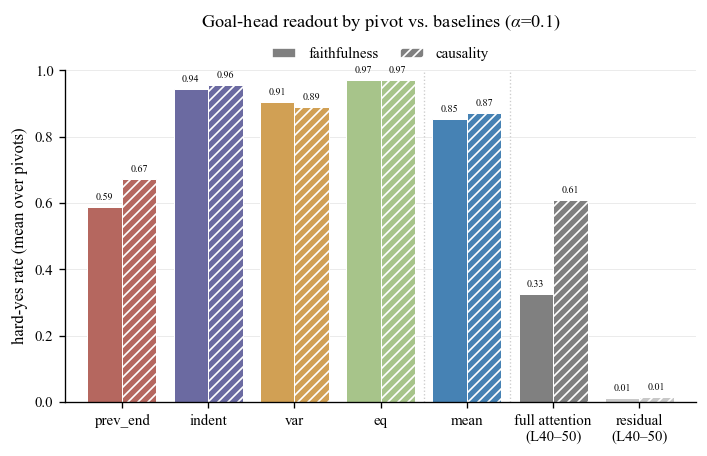

In [6]:
# ── Figure (paper fig:heads-vs-residual): goal-head readout by pivot + L40--50 baselines ──
# Merged view: goal-head readout broken out per pre-impl pivot + the mean, then only the
# L40--50 full-attention and residual baselines appended for comparison (additive, alpha=0.1).
import glob, json, numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
M='Qwen2.5-Coder-32B-Instruct'; PIV=F.PIVOTS
def by_pivot(strat,pat,mode):
    g=glob.glob(f'{V2_GS if mode=="causality" else "results"}/goalscope/{M}/{mode}/{strat}/{pat}/summary.json')
    if not g: return {a:np.nan for a in PIV}
    d=json.load(open(g[0]))['by_anchor']; return {a:float(d[a]['hard_yes']) for a in PIV}
def mean4(strat,pat,mode):
    d=by_pivot(strat,pat,mode); return float(np.nanmean([d[a] for a in PIV]))

# goal heads, per pivot (additive_norm/0.1)
gh_f=by_pivot('additive_norm/0.1','heads=goal__*','faithfulness')
gh_c=by_pivot('additive_norm/0.1','heads=goal__*','causality')
# appended L40--50 baselines (resid_norm/0.1), aggregated as mean over the four pivots
BASE=[('full attention\n(L40–50)','heads=attn:L40-50:mean*','#808080'),
      ('residual\n(L40–50)',      'heads=resid:L40-50:mean*','#c8c8c8')]

labels=list(PIV)+['mean']+[b[0] for b in BASE]
cols  =[F.PIVOT_COLOR[a] for a in PIV]+['#4682B4']+[b[2] for b in BASE]
faith =[gh_f[a] for a in PIV]+[np.mean([gh_f[a] for a in PIV])]+[mean4('resid_norm/0.1',b[1],'faithfulness') for b in BASE]
caus  =[gh_c[a] for a in PIV]+[np.mean([gh_c[a] for a in PIV])]+[mean4('resid_norm/0.1',b[1],'causality')    for b in BASE]

SP=0.70                                   # group spacing (<1 -> tighter groups)
pos=np.arange(len(labels))*SP
fig,ax=plt.subplots(figsize=(6.0,3.9)); w=0.28  # thinner bars, narrower fig, tighter groups
for xi in range(len(labels)):
    ax.bar(pos[xi]-w/2, faith[xi], w, **F.metric_kw('faithfulness', cols[xi]))
    ax.bar(pos[xi]+w/2, caus[xi],  w, **F.metric_kw('causality',    cols[xi]))
    ax.text(pos[xi]-w/2, faith[xi]+.015, f'{faith[xi]:.2f}', ha='center', va='bottom', fontsize=6)
    ax.text(pos[xi]+w/2, caus[xi]+.015,  f'{caus[xi]:.2f}',  ha='center', va='bottom', fontsize=6)
ax.set_xticks(pos); ax.set_xticklabels(labels); ax.set_xlim(-w-0.18, pos[-1]+w+0.18)
ax.set_ylabel('hard-yes rate (mean over pivots)'); ax.set_ylim(0,1.0)
ax.xaxis.grid(False)  # keep only horizontal gridlines
ax.set_title('Goal-head readout by pivot vs. baselines ($\\alpha$=0.1)')
ax.axvline((len(PIV)-0.5)*SP, color='#ccc', lw=.8, ls=':')   # goal-head pivots | mean
ax.axvline((len(PIV)+0.5)*SP, color='#ccc', lw=.8, ls=':')   # mean | L40--50 baselines
_h=F.metric_legend_handles(); F.legend_top(ax, handles=_h, labels=[h.get_label() for h in _h])
fig.tight_layout(); print('saved', F.save_fig(fig,OUT,'fig02_fig12_source_comparison')); plt.show()


## Model generalization (App F, Figs 15-17) — replace at each model's best causality_auto α

All three axes use the **replace** strategy (Fig 16 moves off additive_norm 0.1). For each model the α is the one with the
best causality_auto mean4 among α ∈ {1, 1.5, 2} that has finished; faithfulness is drawn **at that same α** (one config
per model). Faithfulness roots: α 1 = `results/`, α > 1 = `results_faith_bestalpha/` (scratch root; never `results/`).
A faithfulness leaf that has not finished yet is skipped with a warning: re-run after the replace grid completes.

In [7]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json, glob
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
GROUP=OUT; PIV=F.PIVOTS
ALPHAS=['1','1.5','2']                                     # leaf dir names for alpha 1.0 / 1.5 / 2.0
FAITH_ROOT={'1':'results','1.5':'results','2':'results'}
CAUS_ROOT='results'
# per-model head spec (= Table 2): Olmo uses the INTENTIONALLY BALANCED sets (93/91); the others their own `goal` set.
HSPEC={'Olmo-3.1-32B-Instruct':'json:goal__lam20_thr1.0_band10-36',
       'Olmo-3.1-32B-Instruct-SFT':'json:goal__lam20_thr0.6_band10-36'}
def leaf(model,mode,alpha):
    root=CAUS_ROOT if mode=='causality' else FAITH_ROOT[alpha]
    spec=HSPEC.get(model,'goal')
    g=[p for p in glob.glob(f'{root}/goalscope/{model}/{mode}/replace/{alpha}/heads={spec}__*/summary.json')
       if '__aprefill=' not in p and 'nspec=253' in p]
    return json.load(open(g[0])) if g else None
def curve(model,mode,alpha):
    d=leaf(model,mode,alpha); return None if d is None else [d['by_anchor'][a]['hard_yes'] for a in PIV]
def best_alpha(model):
    m={a:np.mean(c) for a in ALPHAS if (c:=curve(model,'causality',a))}
    return max(m,key=m.get), m
AXES={
  'model_size':      ('Model size (Qwen2.5-Coder 14B vs 32B)',
                      ['Qwen2.5-Coder-14B-Instruct','Qwen2.5-Coder-32B-Instruct']),
  'code_finetuning': ('Code fine-tuning (Coder vs non-Coder, 32B)',
                      ['Qwen2.5-32B-Instruct','Qwen2.5-Coder-32B-Instruct']),
  'rl_finetuning':   ('RL fine-tuning (OLMo-3.1-32B Instruct vs SFT)',
                      ['Olmo-3.1-32B-Instruct-SFT','Olmo-3.1-32B-Instruct']),
}
FIGNUM={'model_size':'fig15','code_finetuning':'fig16','rl_finetuning':'fig17'}  # current paper figure numbers
BEST={}
for m in sorted({m for _,ms in AXES.values() for m in ms}):
    a,ms=best_alpha(m); BEST[m]=a
    f=curve(m,'faithfulness',a)
    print(f"{m:28s} causality_auto mean4 by alpha: "+', '.join(f'{k}={v:.3f}' for k,v in ms.items())
          +f"  -> best alpha {a};  faithfulness@{a} = "+(f'{np.mean(f):.3f}' if f else 'PENDING'))

Olmo-3.1-32B-Instruct        causality_auto mean4 by alpha: 1=0.542, 1.5=0.680, 2=0.731  -> best alpha 2;  faithfulness@2 = 0.691
Olmo-3.1-32B-Instruct-SFT    causality_auto mean4 by alpha: 1=0.330, 1.5=0.487, 2=0.553  -> best alpha 2;  faithfulness@2 = 0.678
Qwen2.5-32B-Instruct         causality_auto mean4 by alpha: 1=0.620  -> best alpha 1;  faithfulness@1 = 0.238
Qwen2.5-Coder-14B-Instruct   causality_auto mean4 by alpha: 1=0.211, 1.5=0.439, 2=0.625  -> best alpha 2;  faithfulness@2 = 0.789
Qwen2.5-Coder-32B-Instruct   causality_auto mean4 by alpha: 1=0.870, 1.5=0.917, 2=0.885  -> best alpha 1.5;  faithfulness@1.5 = 0.907


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/causality_auto/fig15_model_size.pdf


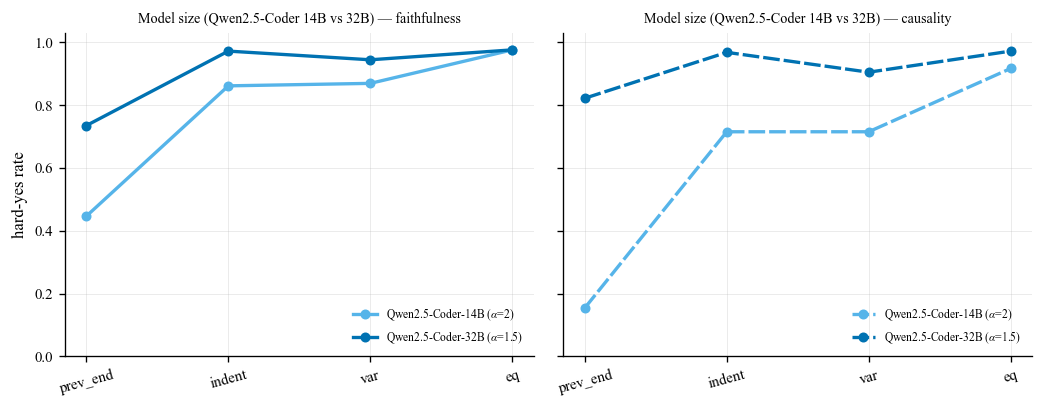

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/causality_auto/fig16_code_finetuning__optA_replace_best_alpha.pdf


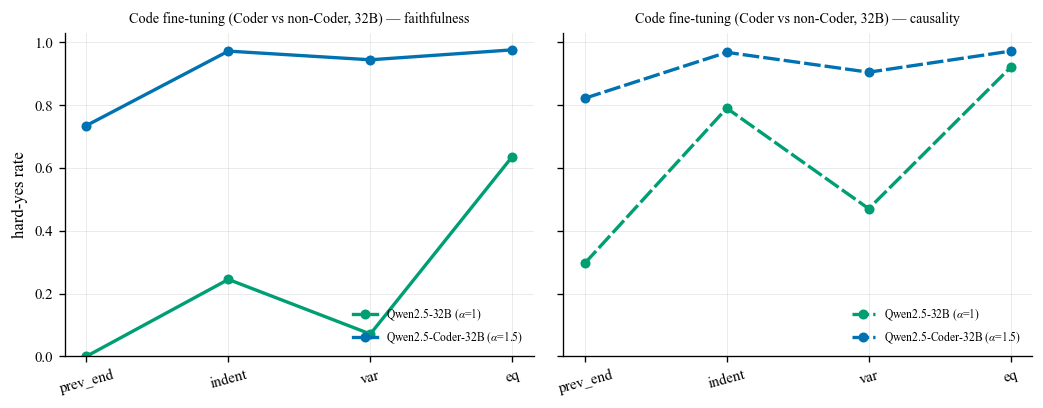

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/causality_auto/fig17_rl_finetuning.pdf


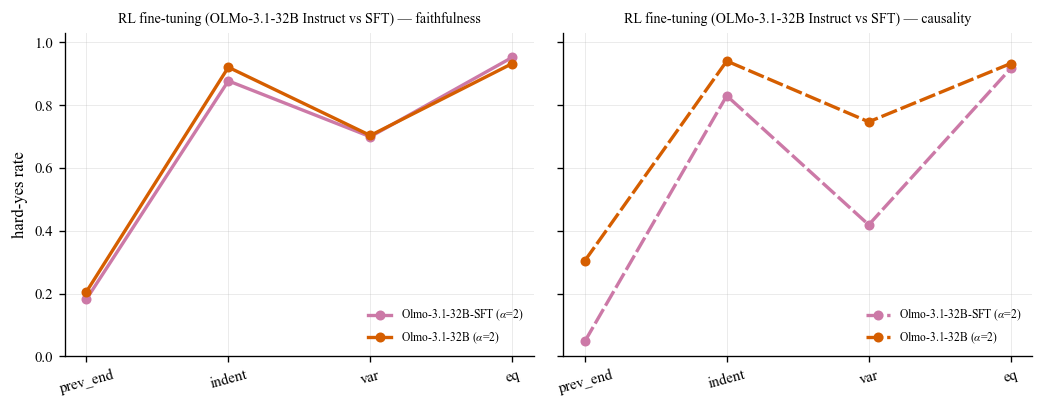

In [8]:
# one figure per axis, as in the paper: faithfulness (left, solid) | causality_auto (right, tight dash),
# both panels at each model's best causality_auto alpha.
for name,(title,models) in AXES.items():
    fig,axes=plt.subplots(1,2,figsize=(8.8,3.5),sharey=True); x=np.arange(len(PIV))
    for ax,mode in zip(axes,['faithfulness','causality']):
        ls='-' if mode=='faithfulness' else (0,(5,1.2))
        for m in models:
            a=BEST[m]; c=curve(m,mode,a)
            if c is None:
                print(f'WARNING: {m} {mode} at alpha {a} not finished; curve skipped'); continue
            ax.plot(x,c,marker='o',ls=ls,color=F.MODEL_COLOR.get(m,'#777'),lw=2,ms=5,
                    label=f"{m.replace('-Instruct','')} ($\\alpha$={float(a):g})")
        ax.set_xticks(x); ax.set_xticklabels(PIV,rotation=15); ax.set_ylim(0,1.03)
        ax.set_title(f'{title} — {mode}',fontsize=8.5)
        ax.legend(fontsize=7,frameon=False,loc='lower right')
    axes[0].set_ylabel('hard-yes rate')
    fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,f'{FIGNUM[name]}_{name}'+('__optA_replace_best_alpha' if name=='code_finetuning' else ''))); plt.show()

option B Qwen2.5-32B-Instruct         faithfulness mean4 0.766
option B Qwen2.5-Coder-32B-Instruct   faithfulness mean4 0.853
option B Qwen2.5-32B-Instruct         causality    mean4 0.778
option B Qwen2.5-Coder-32B-Instruct   causality    mean4 0.873


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/causality_auto/fig16_code_finetuning__optB_additive_coder122.pdf


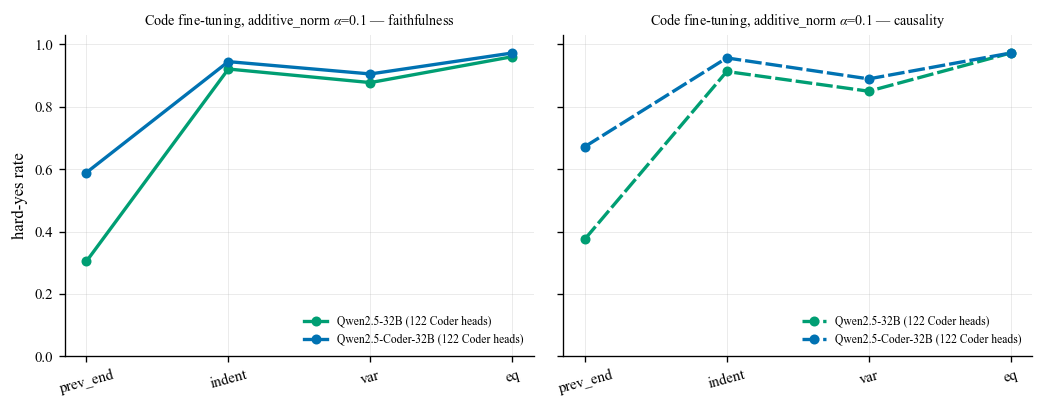

In [9]:
# Fig 16, option B (decision pending): the paper's current method -- additive_norm alpha 0.1, both LMs with the
# Coder's 122 heads -- with causality_auto. Faithfulness = the paper's leaves in results/ (unchanged).
B_MODELS=['Qwen2.5-32B-Instruct','Qwen2.5-Coder-32B-Instruct']
B_SPEC={'faithfulness':{'Qwen2.5-32B-Instruct':'json:coder32b_goal122','Qwen2.5-Coder-32B-Instruct':'goal'},
        # v2 ran the identical 122 [layer, head] list from a differently named file
        'causality':  {'Qwen2.5-32B-Instruct':'json:goal__lam20_thr0.9_band25-56','Qwen2.5-Coder-32B-Instruct':'goal'}}
def curve_B(model,mode):
    root=CAUS_ROOT if mode=='causality' else 'results'
    g=[p for p in glob.glob(f'{root}/goalscope/{model}/{mode}/additive_norm/0.1/heads={B_SPEC[mode][model]}__*/summary.json') if 'nspec=253' in p]
    d=json.load(open(g[0]))['by_anchor']; return [d[a]['hard_yes'] for a in PIV]
fig,axes=plt.subplots(1,2,figsize=(8.8,3.5),sharey=True); x=np.arange(len(PIV))
for ax,mode in zip(axes,['faithfulness','causality']):
    ls='-' if mode=='faithfulness' else (0,(5,1.2))
    for m in B_MODELS:
        c=curve_B(m,mode); print(f'option B {m:28s} {mode:12s} mean4 {np.mean(c):.3f}')
        ax.plot(x,c,marker='o',ls=ls,color=F.MODEL_COLOR.get(m,'#777'),lw=2,ms=5,label=m.replace('-Instruct','')+' (122 Coder heads)')
    ax.set_xticks(x); ax.set_xticklabels(PIV,rotation=15); ax.set_ylim(0,1.03)
    ax.set_title(f'Code fine-tuning, additive_norm $\\alpha$=0.1 — {mode}',fontsize=8.5)
    ax.legend(fontsize=7,frameon=False,loc='lower right')
axes[0].set_ylabel('hard-yes rate')
fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,'fig16_code_finetuning__optB_additive_coder122')); plt.show()

## OVReader (App G) — Qwen2.5-Coder-32B

In [10]:
import numpy as np
import matplotlib.pyplot as plt

import figstyle
from scripts.evaluation import ov_reader_io as ovio

figstyle.set_style()

MODEL   = "Qwen/Qwen2.5-Coder-32B-Instruct"
MSLUG   = MODEL.split("/")[-1]
PIVOT   = "eq"                      # assignment pivot = main OVReader position
RR      = env_utils.determine_results_dir()
SKY     = ovio.SKYLINE_IDX          # "goalscope"

def load_metric(mode, pivot=PIVOT):
    """Return (layers, dtypes, {dt: hard_yes-over-layers}, {dt: goalscope-ref}) at `pivot`."""
    df = ovio.grid_df(V2_OV if mode == "causality" else RR, mode=mode, model=MODEL)
    df = df[df["pivot"] == pivot]
    piv = df.pivot_table(index="layer_idx", columns="datatype", values="hard_yes")
    dtypes = sorted(piv.columns.tolist())
    ref = {dt: (piv.loc[SKY, dt] if SKY in piv.index else np.nan) for dt in dtypes}
    piv = piv.drop(index=SKY, errors="ignore")
    layers = sorted(int(x) for x in piv.index)
    curves = {dt: piv.loc[layers, dt].to_numpy(dtype=float) for dt in dtypes}
    return layers, dtypes, curves, ref

FAI = load_metric("faithfulness")
CAU = load_metric("causality")
DTYPES = FAI[1]
DT_COLOR = {dt: figstyle.OKABE_ITO[i] for i, dt in enumerate(DTYPES)}
print("layers:", FAI[0])
print("datatypes:", DTYPES)
print("pre-impl pivots available in figstyle:", figstyle.PIVOTS)

layers: [0, 6, 12, 18, 24, 30, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 60, 63]
datatypes: ['int', 'list[int]', 'list[str]', 'str']
pre-impl pivots available in figstyle: ['prev_end', 'indent', 'var', 'eq']


122-head set across layers 28-55; peak 12 heads @ L49


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/causality_auto/fig18_ov_reader_combined.pdf
faithfulness peak (4-pivot mean) = 0.771 @ layer 50 | goalscope ref = 0.853
causality    peak (4-pivot mean) = 0.773 @ layer 50 | goalscope ref = 0.876
goal-head density peak @ L49 (mass in L45-52: 68/122)


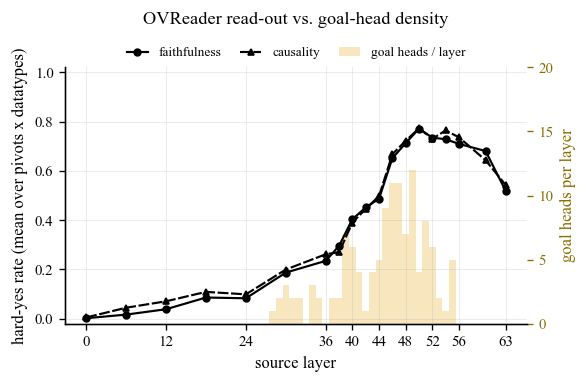

In [11]:
import json, collections
CAUS_DASH = (0, (5, 1.2))          # tight dashes = causality style (shared)

# ── readout: mean over the 4 pre-impl pivots AND the 4 datatypes ──
def metric_over_pivots(mode):
    """(layers, mean-hard_yes over 4 pivots x 4 datatypes, goalscope-ref mean)."""
    per_pivot_means, refs = [], []
    x = None
    for piv in figstyle.PIVOTS:                      # prev_end, indent, var, eq (no first_impl)
        layers, _, curves, ref = load_metric(mode, piv)
        x = np.array(layers)
        per_pivot_means.append(np.nanmean(np.stack([curves[dt] for dt in DTYPES]), axis=0))
        refs.append(np.nanmean([ref[dt] for dt in DTYPES]))
    return x, np.nanmean(np.stack(per_pivot_means), axis=0), float(np.nanmean(refs))

xf, mf, rf = metric_over_pivots("faithfulness")
xc, mc, rc = metric_over_pivots("causality")

# ── goal-head density per layer (122-head set), loaded from the head_set file ──
HEAD_SET = "head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_thr0.9_band25-56.json"
_pairs = json.load(open(HEAD_SET))
_counts = collections.Counter(l for l, h in _pairs)
dens_layers = np.array(sorted(_counts))
dens_counts = np.array([_counts[l] for l in dens_layers])
print(f"{len(_pairs)}-head set across layers {dens_layers.min()}-{dens_layers.max()};"
      f" peak {dens_counts.max()} heads @ L{int(dens_layers[dens_counts.argmax()])}")

GOLD = "#E69F00"
LW, MS = 1.3, 4                    # thinner curves, slightly smaller markers

fig, ax = plt.subplots(figsize=(5.0, 3.3))

# density overlay on a faint secondary right axis, drawn BEHIND the curves
ax2 = ax.twinx()
ax2.bar(dens_layers, dens_counts, width=1.0, color=GOLD, alpha=0.25, zorder=0, linewidth=0)
ax2.set_ylabel("goal heads per layer", color="#8a6d00")
ax2.tick_params(axis="y", colors="#8a6d00")
ax2.set_ylim(0, 20)
ax2.set_yticks([0, 5, 10, 15, 20])
ax2.grid(False)
# put the curve axis on top of the density bars
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)

# readout curves: both BLACK, faithfulness solid, causality tight-dash
ax.plot(xf, mf, marker="o", ms=MS, lw=LW, color="black", ls="-", label="faithfulness", zorder=5)
ax.plot(xc, mc, marker="^", ms=MS, lw=LW, color="black", ls=CAUS_DASH, label="causality", zorder=5)

ax.set_xlabel("source layer")
ax.set_ylabel("hard-yes rate (mean over pivots x datatypes)")
ax.set_title(r"OVReader read-out vs. goal-head density")
ax.set_ylim(-0.02, 1.02)
ax.set_xticks(xf[::2])

# legend: single row on top, just below the title
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
handles = [
    Line2D([], [], color="black", ls="-", marker="o", ms=MS, lw=LW, label="faithfulness"),
    Line2D([], [], color="black", ls=CAUS_DASH, marker="^", ms=MS, lw=LW, label="causality"),
    Patch(facecolor=GOLD, alpha=0.25, label="goal heads / layer"),
]
figstyle.legend_top(ax, handles=handles, labels=[h.get_label() for h in handles], fontsize=8)
fig.tight_layout()
p = figstyle.save_fig(fig, OUT, "fig18_ov_reader_combined")
print("saved", p)
print(f"faithfulness peak (4-pivot mean) = {np.nanmax(mf):.3f} @ layer {int(xf[np.nanargmax(mf)])} "
      f"| goalscope ref = {rf:.3f}")
print(f"causality    peak (4-pivot mean) = {np.nanmax(mc):.3f} @ layer {int(xc[np.nanargmax(mc)])} "
      f"| goalscope ref = {rc:.3f}")
print(f"goal-head density peak @ L{int(dens_layers[dens_counts.argmax()])} "
      f"(mass in L45-52: {dens_counts[(dens_layers>=45)&(dens_layers<=52)].sum()}/{dens_counts.sum()})")

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/causality_auto/fig19_ov_by_pivot_combined.pdf


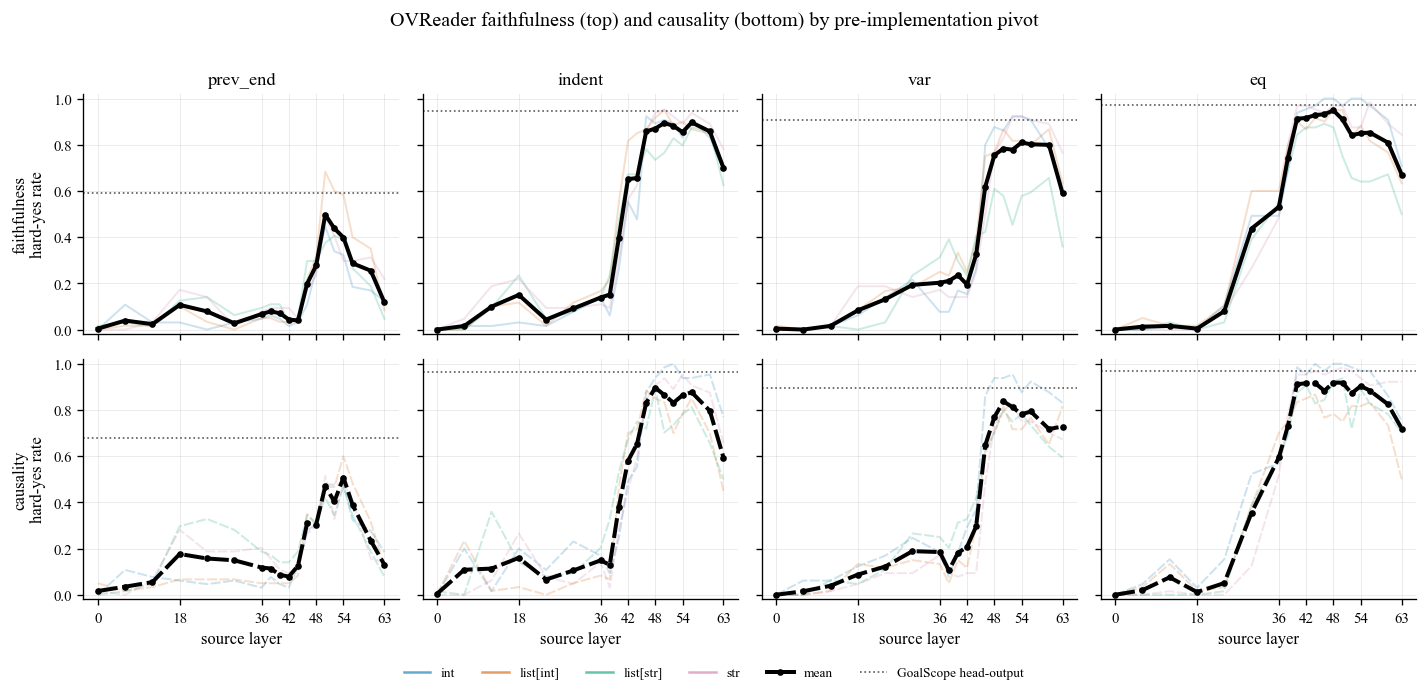

In [12]:
# 2-ROW combined per-pivot figure: row 0 = faithfulness, row 1 = causality (4 pre-impl pivots).
# Merges fig:ov-faithfulness + fig:ov-causality into one appendix figure (ov_by_pivot_combined).
from matplotlib.lines import Line2D
PANEL_PIVOTS = list(figstyle.PIVOTS)
CAUS_DASH = (0, (5, 1.2))

def plot_by_pivot_combined(save_name="fig19_ov_by_pivot_combined"):
    modes = [("faithfulness", "-"), ("causality", CAUS_DASH)]
    fig, axes = plt.subplots(len(modes), len(PANEL_PIVOTS),
                             figsize=(3.0 * len(PANEL_PIVOTS), 2.7 * len(modes)),
                             sharex=True, sharey=True)
    for row, (mode, ls) in enumerate(modes):
        for col, piv in enumerate(PANEL_PIVOTS):
            ax = axes[row, col]
            layers, _, curves, ref = load_metric(mode, piv)
            x = np.array(layers)
            mean = np.nanmean(np.stack([curves[dt] for dt in DTYPES]), axis=0)
            refm = float(np.nanmean([ref[dt] for dt in DTYPES]))
            for dt in DTYPES:
                ax.plot(x, curves[dt], lw=1.2, ls=ls, color=DT_COLOR[dt], alpha=0.2)
            ax.plot(x, mean, marker="o", ms=3, lw=2.4, ls=ls, color="black", zorder=5)
            ax.axhline(refm, ls=":", lw=1.0, color="0.35")
            ax.set_ylim(-0.02, 1.02)
            ax.set_xticks(x[::3])
            if row == 0:
                ax.set_title(piv)
            if row == len(modes) - 1:
                ax.set_xlabel("source layer")
        axes[row, 0].set_ylabel(f"{mode}\nhard-yes rate")
    handles = ([Line2D([], [], color=DT_COLOR[dt], lw=1.5, alpha=0.6, label=dt) for dt in DTYPES]
               + [Line2D([], [], color="black", marker="o", ms=3, lw=2.4, label="mean"),
                  Line2D([], [], color="0.35", ls=":", lw=1.0, label="GoalScope head-output")])
    fig.legend(handles=handles, frameon=False, fontsize=8, ncol=len(handles),
               loc="lower center", bbox_to_anchor=(0.5, -0.04))
    fig.suptitle("OVReader faithfulness (top) and causality (bottom) by pre-implementation pivot", y=1.01)
    fig.tight_layout()
    p = figstyle.save_fig(fig, OUT, save_name)
    print("saved", p)
    return fig

_ = plot_by_pivot_combined()